# ACDC Cardiac MRI Classification

**CMPS 261 - Machine Learning Project**

This project aims to classify patients into five cardiac diagnostic groups using the ACDC cardiac MRI dataset. We will construct features from the available MRI data and segmentation masks, then train and evaluate a classical machine learning model.

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [5]:
data_path = "ACDC/database"

patients = []

for folder in ["training", "testing"]:
    folder_path = os.path.join(data_path, folder)

    for patient in sorted(os.listdir(folder_path)):
        if not patient.startswith("patient"):
            continue

        info_path = os.path.join(folder_path, patient, "Info.cfg")

        info = {}

        with open(info_path, "r") as file:
            for line in file:
                key, value = line.strip().split(":")
                info[key.strip()] = value.strip()

        info["Patient"] = patient
        info["Split"] = folder
        patients.append(info)

df = pd.DataFrame(patients)

print(df.shape)
df.head()

(150, 8)


,ED,ES,Group,Height,NbFrame,Weight,Patient,Split
0,1,12,DCM,184.0,30,95.0,patient001,training
1,1,12,DCM,160.0,30,70.0,patient002,training
2,1,15,DCM,165.0,30,77.0,patient003,training
3,1,15,DCM,159.0,28,46.0,patient004,training
4,1,13,DCM,165.0,30,77.0,patient005,training


### Class Distribution

We check the number of patients in each diagnostic group to see if the dataset is balanced.

In [6]:
print(df.groupby(["Split", "Group"]).size())

Split     Group
testing   DCM      10
          HCM      10
          MINF     10
          NOR      10
          RV       10
training  DCM      20
          HCM      20
          MINF     20
          NOR      20
          RV       20
dtype: int64


### MRI Visualization

We load an MRI volume and its segmentation mask to understand the image structure before extracting features.

Image shape: (216, 256, 10)
Mask shape: (216, 256, 10)
Mask labels: [0. 1. 2. 3.]


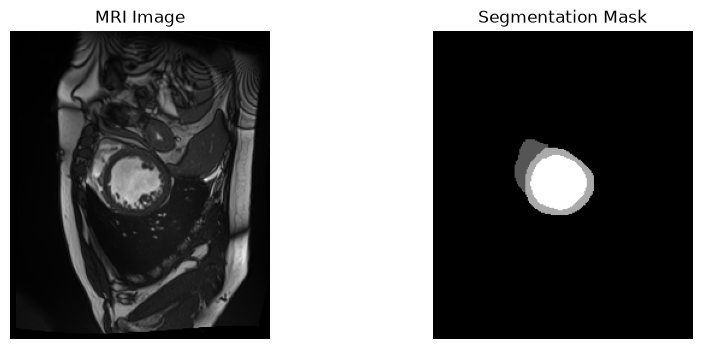

In [7]:
patient_path = os.path.join(data_path, "training", "patient001")

image = nib.load(os.path.join(patient_path, "patient001_frame01.nii.gz"))
mask = nib.load(os.path.join(patient_path, "patient001_frame01_gt.nii.gz"))

image_data = image.get_fdata()
mask_data = mask.get_fdata()

print("Image shape:", image_data.shape)
print("Mask shape:", mask_data.shape)
print("Mask labels:", np.unique(mask_data))

slice_index = image_data.shape[2] // 2

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_data[:, :, slice_index].T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_data[:, :, slice_index].T, cmap="gray", origin="lower")
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()

### Feature Extraction

We extract cardiac volume measurements from the segmentation masks at end-diastole and end-systole. These measurements will be used as features for classification.

In [8]:
ed_mask = nib.load(os.path.join(patient_path, "patient001_frame01_gt.nii.gz"))
es_mask = nib.load(os.path.join(patient_path, "patient001_frame12_gt.nii.gz"))

ed_data = ed_mask.get_fdata()
es_data = es_mask.get_fdata()

voxel_volume = np.prod(ed_mask.header.get_zooms()[:3]) / 1000

lv_ed = np.sum(ed_data == 3) * voxel_volume
lv_es = np.sum(es_data == 3) * voxel_volume

rv_ed = np.sum(ed_data == 1) * voxel_volume
rv_es = np.sum(es_data == 1) * voxel_volume

myo_ed = np.sum(ed_data == 2) * voxel_volume

lv_ef = (lv_ed - lv_es) / lv_ed * 100
rv_ef = (rv_ed - rv_es) / rv_ed * 100

print("LV ED volume:", lv_ed)
print("LV ES volume:", lv_es)
print("RV ED volume:", rv_ed)
print("RV ES volume:", rv_es)
print("Myocardium volume:", myo_ed)
print("LV ejection fraction:", lv_ef)
print("RV ejection fraction:", rv_ef)

LV ED volume: 295.5078125
LV ES volume: 225.6103515625
RV ED volume: 139.7216796875
RV ES volume: 59.5458984375
Myocardium volume: 164.2578125
LV ejection fraction: 23.65333773959022
RV ejection fraction: 57.38249170015726


### Extracting Features for All Patients

We extract ventricular volumes, myocardial volume, and ejection fractions from the ED and ES segmentation masks for each patient.

In [9]:
features = []

for _, row in df.iterrows():
    patient = row["Patient"]
    folder = row["Split"]
    patient_path = os.path.join(data_path, folder, patient)

    ed_frame = int(row["ED"])
    es_frame = int(row["ES"])

    ed_path = os.path.join(patient_path, f"{patient}_frame{ed_frame:02d}_gt.nii.gz")
    es_path = os.path.join(patient_path, f"{patient}_frame{es_frame:02d}_gt.nii.gz")

    ed_mask = nib.load(ed_path)
    es_mask = nib.load(es_path)

    ed_data = ed_mask.get_fdata()
    es_data = es_mask.get_fdata()

    voxel_volume = np.prod(ed_mask.header.get_zooms()[:3]) / 1000

    lv_ed = np.sum(ed_data == 3) * voxel_volume
    lv_es = np.sum(es_data == 3) * voxel_volume

    rv_ed = np.sum(ed_data == 1) * voxel_volume
    rv_es = np.sum(es_data == 1) * voxel_volume

    myo_ed = np.sum(ed_data == 2) * voxel_volume

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    features.append({
        "Patient": patient,
        "Split": folder,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

features_df = pd.DataFrame(features)

print(features_df.shape)
features_df.head()

(150, 10)


,Patient,Split,Group,LV_ED,LV_ES,RV_ED,RV_ES,MYO_ED,LV_EF,RV_EF
0,patient001,training,DCM,295.507812,225.610352,139.721680,59.545898,164.257812,23.653338,57.382492
1,patient002,training,DCM,265.744400,188.303375,94.432068,28.823090,160.433578,29.141169,69.477435
2,patient003,training,DCM,276.708984,241.088867,192.333984,174.584961,191.845703,12.872772,9.228231
3,patient004,training,DCM,260.847092,226.472473,106.264114,84.543991,168.452454,13.178072,20.439754
4,patient005,training,DCM,290.797119,224.094727,170.463867,74.553223,201.392578,22.937776,56.264501


### Data Preprocessing

We check for missing values before preparing the data for training.

In [10]:
print(features_df.shape)
print(features_df.isnull().sum())

(150, 10)
Patient    0
Split      0
Group      0
LV_ED      0
LV_ES      0
RV_ED      0
RV_ES      0
MYO_ED     0
LV_EF      0
RV_EF      0
dtype: int64


### Train and Validation Split

We split the 100 training patients into 80% training and 20% validation using stratified sampling to preserve the class distribution. The original test set is kept separate for final evaluation.

In [11]:
feature_columns = ["LV_ED", "LV_ES", "RV_ED", "RV_ES", "MYO_ED", "LV_EF", "RV_EF"]

train_df = features_df[features_df["Split"] == "training"]
test_df = features_df[features_df["Split"] == "testing"]

X = train_df[feature_columns]
y = train_df["Group"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print(y_train.value_counts())
print(y_val.value_counts())

Training: (80, 7)
Validation: (20, 7)
Group
RV      16
NOR     16
MINF    16
HCM     16
DCM     16
Name: count, dtype: int64
Group
MINF    4
DCM     4
NOR     4
HCM     4
RV      4
Name: count, dtype: int64


### Feature Standardization

We standardize the numerical features so they have a mean of 0 and a standard deviation of 1. The scaler is fitted only on the training data to avoid data leakage.

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

print("Training means:", X_train_scaled.mean(axis=0))
print("Training standard deviations:", X_train_scaled.std(axis=0))

Training shape: (80, 7)
Validation shape: (20, 7)
Training means: [-7.77156117e-17  0.00000000e+00  1.99840144e-16 -4.99600361e-17
  1.11022302e-17  2.66453526e-16  6.66133815e-17]
Training standard deviations: [1. 1. 1. 1. 1. 1. 1.]


### Logistic Regression Baseline

We train a logistic regression model using the standardized features and evaluate its performance on the validation set using accuracy and macro-F1.

In [13]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

y_val_pred = lr.predict(X_val_scaled)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Macro-F1:", f1_score(y_val, y_val_pred, average="macro"))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.85
Validation Macro-F1: 0.8520634920634921
              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       1.00      0.75      0.86         4
        MINF       0.67      1.00      0.80         4
         NOR       0.80      1.00      0.89         4
          RV       1.00      0.75      0.86         4

    accuracy                           0.85        20
   macro avg       0.89      0.85      0.85        20
weighted avg       0.89      0.85      0.85        20



### Hyperparameter Tuning

We compare different regularization strengths for logistic regression and select the value with the highest validation macro-F1 score.

In [14]:
c_values = [0.01, 0.1, 1, 10, 100]

results = []

for c in c_values:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average="macro")

    results.append({
        "C": c,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

results_df = pd.DataFrame(results)

results_df

,C,Accuracy,Macro-F1
0,0.01,0.95,0.949206
1,0.10,0.85,0.852063
2,1.00,0.85,0.852063
3,10.00,0.90,0.898413
4,100.00,0.90,0.898413


### Best Model Evaluation

We evaluate the selected logistic regression model on the validation set and examine its confusion matrix to identify classification errors.

Validation Accuracy: 0.95
Validation Macro-F1: 0.9492063492063492
              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       1.00      1.00      1.00         4
        MINF       0.80      1.00      0.89         4
         NOR       1.00      1.00      1.00         4
          RV       1.00      1.00      1.00         4

    accuracy                           0.95        20
   macro avg       0.96      0.95      0.95        20
weighted avg       0.96      0.95      0.95        20



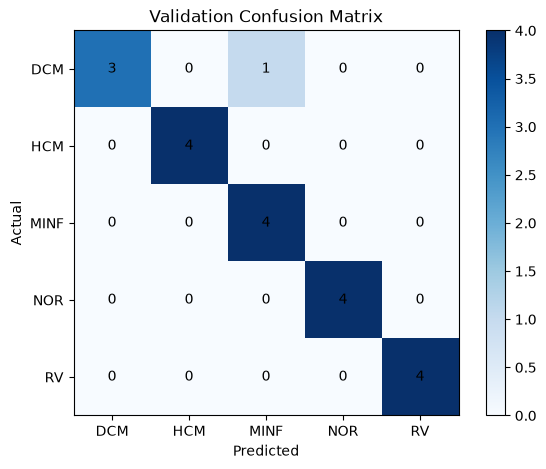

In [15]:
best_lr = LogisticRegression(C=0.01, max_iter=1000, random_state=42)

best_lr.fit(X_train_scaled, y_train)

y_val_pred = best_lr.predict(X_val_scaled)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Macro-F1:", f1_score(y_val, y_val_pred, average="macro"))
print(classification_report(y_val, y_val_pred))

classes = best_lr.classes_
cm = confusion_matrix(y_val, y_val_pred, labels=classes)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation Confusion Matrix")

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

### Cross-Validation

We use 5-fold stratified cross-validation to check how consistently the selected model performs across different training and validation splits.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=1000, random_state=42)
)

cv_scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")

print("Cross-validation Macro-F1:", cv_scores)
print("Mean Macro-F1:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation Macro-F1: [0.94920635 0.84920635 0.85021645 0.88888889 0.74444444]
Mean Macro-F1: 0.8563924963924963
Standard deviation: 0.06677211602479663


### Cross-Validation Tuning

We compare different regularization strengths using 5-fold stratified cross-validation to select a model that performs consistently across different splits.

In [17]:
cv_results = []

for c in c_values:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=c, max_iter=1000, random_state=42)
    )

    scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")

    cv_results.append({
        "C": c,
        "Mean Macro-F1": scores.mean(),
        "Std Macro-F1": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,C,Mean Macro-F1,Std Macro-F1
0,0.01,0.856392,0.066772
1,0.10,0.911408,0.079397
2,1.00,0.929408,0.075120
3,10.00,0.919250,0.067982
4,100.00,0.888773,0.048815


### Final Classical Baseline

Based on cross-validation, we select logistic regression with L2 regularization and C = 1.0. We retrain the model using all 100 training patients. The test set remains separate for final evaluation.

In [18]:
best_c = cv_results_df.loc[cv_results_df["Mean Macro-F1"].idxmax(), "C"]

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=best_c, max_iter=1000, random_state=42)
)

final_model.fit(X, y)

print("Selected C:", best_c)
print("Training patients:", len(X))
print("Best CV Macro-F1:", cv_results_df["Mean Macro-F1"].max())

Selected C: 1.0
Training patients: 100
Best CV Macro-F1: 0.9294083694083695


### Final Evaluation on the Test Set

We evaluate the Logistic Regression model on the 50 official testing patients using cardiac features extracted from expert segmentation masks. The model was trained on all 100 training patients, and the test set was not used during training or hyperparameter selection.

In [38]:
X_test = test_df[feature_columns]
y_test = test_df["Group"]

y_test_pred = final_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Macro-F1:", f1_score(y_test, y_test_pred, average="macro"))

print()
print(classification_report(y_test, y_test_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=final_model.classes_))

Test Accuracy: 0.9
Test Macro-F1: 0.8999498746867168

              precision    recall  f1-score   support

         DCM       0.80      0.80      0.80        10
         HCM       1.00      0.90      0.95        10
        MINF       0.80      0.80      0.80        10
         NOR       0.91      1.00      0.95        10
          RV       1.00      1.00      1.00        10

    accuracy                           0.90        50
   macro avg       0.90      0.90      0.90        50
weighted avg       0.90      0.90      0.90        50

Confusion Matrix:
[[ 8  0  2  0  0]
 [ 0  9  0  1  0]
 [ 2  0  8  0  0]
 [ 0  0  0 10  0]
 [ 0  0  0  0 10]]


## Part 2: Automatic Segmentation and Classification

### Preparing MRI Data

We prepare MRI slices and their corresponding ground-truth segmentation masks. These will be used to train a Random Forest model to identify the background, right ventricle, myocardium, and left ventricle.

In [20]:
seg_images = []
seg_masks = []
seg_patients = []

for _, row in df[df["Split"] == "training"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "training", patient)

    for phase in ["ED", "ES"]:
        frame = int(row[phase])

        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")
        mask_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}_gt.nii.gz")

        image = nib.load(image_path).get_fdata()
        mask = nib.load(mask_path).get_fdata()

        for i in range(image.shape[2]):
            seg_images.append(image[:, :, i])
            seg_masks.append(mask[:, :, i])
            seg_patients.append(patient)

print("Total slices:", len(seg_images))
print("First image shape:", seg_images[0].shape)
print("First mask shape:", seg_masks[0].shape)

Total slices: 1902
First image shape: (216, 256)
First mask shape: (216, 256)


### Pixel Feature Extraction

We prepare pixel intensity and position features for the segmentation model. We sample pixels from the training patients to reduce memory usage and keep the validation patients separate.

In [21]:
rng = np.random.default_rng(42)

train_patients = set(train_df.loc[X_train.index, "Patient"])
val_patients = set(train_df.loc[X_val.index, "Patient"])

X_seg_train = []
y_seg_train = []

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    height, width = image.shape

    yy, xx = np.indices(image.shape)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / width).ravel(),
        (yy / height).ravel()
    ))

    labels = mask.ravel().astype(int)

    indices = rng.choice(len(labels), size=min(200, len(labels)), replace=False)

    X_seg_train.append(pixel_features[indices])
    y_seg_train.append(labels[indices])

X_seg_train = np.vstack(X_seg_train)
y_seg_train = np.concatenate(y_seg_train)

print("Training pixels:", X_seg_train.shape)
print("Labels:", np.unique(y_seg_train, return_counts=True))
print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

Training pixels: (300800, 3)
Labels: (array([0, 1, 2, 3]), array([289347,   3824,   3804,   3825]))
Training patients: 80
Validation patients: 20


### Class Balancing

Most pixels belong to the background class. We balance the training data by randomly sampling an equal number of pixels from each class so the model can learn the cardiac structures more effectively.

In [22]:
class_counts = np.bincount(y_seg_train)
min_count = class_counts.min()

balanced_indices = []

for label in range(4):
    indices = np.where(y_seg_train == label)[0]
    selected = rng.choice(indices, size=min_count, replace=False)
    balanced_indices.extend(selected)

balanced_indices = np.array(balanced_indices)
rng.shuffle(balanced_indices)

X_seg_balanced = X_seg_train[balanced_indices]
y_seg_balanced = y_seg_train[balanced_indices]

print("Balanced training shape:", X_seg_balanced.shape)
print("Class counts:", np.unique(y_seg_balanced, return_counts=True))

Balanced training shape: (15216, 3)
Class counts: (array([0, 1, 2, 3]), array([3804, 3804, 3804, 3804]))


### Random Forest Segmentation

We train a Random Forest classifier to predict the segmentation label of each pixel using its intensity and position. The model predicts background, right ventricle, myocardium, or left ventricle.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_seg = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg.fit(X_seg_balanced, y_seg_balanced)

print("Random Forest training completed")
print("Number of trees:", rf_seg.n_estimators)
print("Number of training pixels:", len(X_seg_balanced))

Random Forest training completed
Number of trees: 100
Number of training pixels: 15216


### Segmentation Prediction

We use the trained Random Forest to predict the segmentation mask of a validation MRI slice and compare it with the ground-truth mask.

Validation patient: patient007
Predicted labels: [0 1 2 3]


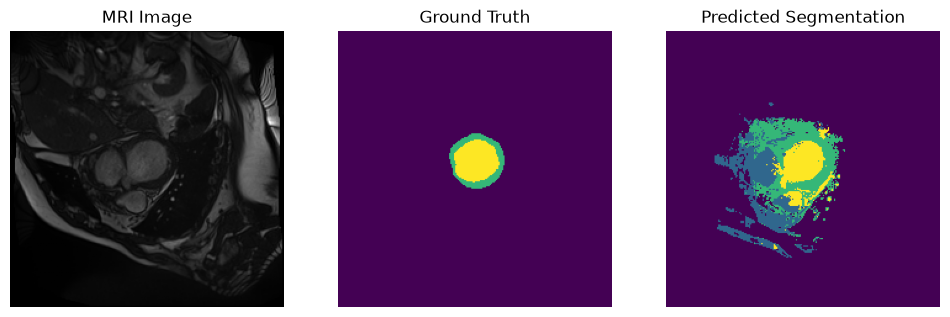

In [24]:
val_patient = sorted(val_patients)[0]

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient == val_patient and np.any(mask > 0):
        val_image = image
        val_mask = mask
        break

val_image = val_image.astype(np.float32)
val_image = (val_image - val_image.mean()) / (val_image.std() + 1e-8)

height, width = val_image.shape
yy, xx = np.indices(val_image.shape)

val_features = np.column_stack((
    val_image.ravel(),
    (xx / width).ravel(),
    (yy / height).ravel()
))

pred_mask = rf_seg.predict(val_features).reshape(height, width)

print("Validation patient:", val_patient)
print("Predicted labels:", np.unique(pred_mask))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Predicted Segmentation")
plt.axis("off")

plt.show()

### Segmentation Evaluation

We evaluate the predicted segmentation using the Dice coefficient, which measures the overlap between predicted and ground-truth regions. We calculate Dice separately for the right ventricle, myocardium, and left ventricle.

In [25]:
dice_scores = {}

for label, name in [(1, "RV"), (2, "Myocardium"), (3, "LV")]:
    predicted = pred_mask == label
    actual = val_mask == label

    intersection = np.sum(predicted & actual)
    total = np.sum(predicted) + np.sum(actual)

    dice = 2 * intersection / total if total > 0 else 1.0
    dice_scores[name] = dice

    print(name, "Dice:", round(dice, 4))

print("Mean Dice:", round(np.mean(list(dice_scores.values())), 4))

RV Dice: 0.0
Myocardium Dice: 0.356
LV Dice: 0.7505
Mean Dice: 0.3689


### Improving Pixel Sampling

The initial segmentation model produced noisy predictions and false positives. We improve the training data by sampling pixels from each class separately, keeping more background examples while ensuring that the cardiac structures are represented.

In [26]:
X_seg_improved = []
y_seg_improved = []

rng = np.random.default_rng(42)

samples_per_class = {
    0: 500,
    1: 200,
    2: 200,
    3: 200
}

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    height, width = image.shape
    yy, xx = np.indices(image.shape)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / width).ravel(),
        (yy / height).ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_improved.append(pixel_features[selected])
        y_seg_improved.append(labels[selected])

X_seg_improved = np.vstack(X_seg_improved)
y_seg_improved = np.concatenate(y_seg_improved)

print("Training pixels:", X_seg_improved.shape)
print("Class counts:", np.unique(y_seg_improved, return_counts=True))

Training pixels: (1525573, 3)
Class counts: (array([0, 1, 2, 3]), array([752000, 224566, 285384, 263623]))


### Retraining the Segmentation Model

We retrain the Random Forest using the improved pixel sampling strategy. We keep the same hyperparameters to compare its performance with the original model.

In [27]:
rf_seg_improved = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_improved.fit(X_seg_improved, y_seg_improved)

print("Improved Random Forest training completed")
print("Number of training pixels:", len(X_seg_improved))

Improved Random Forest training completed
Number of training pixels: 1525573


### Comparing Segmentation Models

We compare the original and improved Random Forest models on the same validation MRI slice. We visualize their predicted masks and calculate Dice scores for each cardiac structure to determine whether the new sampling strategy improved segmentation.

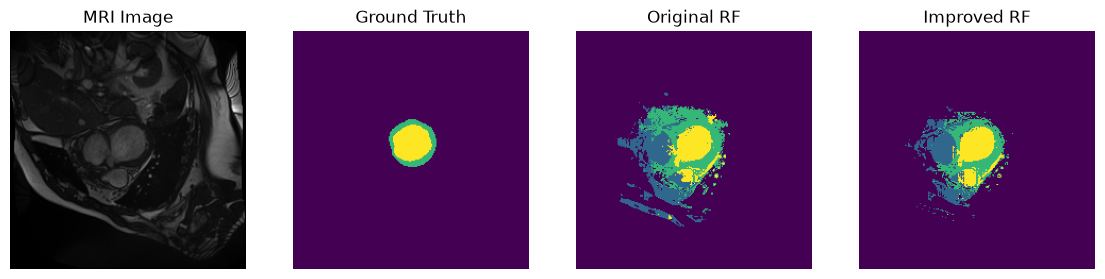

Dice Score Comparison
RV Original: 0.0 Improved: 0.0
Myocardium Original: 0.356 Improved: 0.4815
LV Original: 0.7505 Improved: 0.7547


In [29]:
pred_mask_improved = rf_seg_improved.predict(val_features).reshape(val_image.shape)

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Original RF")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(pred_mask_improved.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Improved RF")
plt.axis("off")

plt.show()

print("Dice Score Comparison")

for label, name in [(1, "RV"), (2, "Myocardium"), (3, "LV")]:
    actual = val_mask == label

    original = pred_mask == label
    improved = pred_mask_improved == label

    original_total = np.sum(original) + np.sum(actual)
    improved_total = np.sum(improved) + np.sum(actual)

    original_dice = 2 * np.sum(original & actual) / original_total if original_total > 0 else 1.0
    improved_dice = 2 * np.sum(improved & actual) / improved_total if improved_total > 0 else 1.0

    print(name, "Original:", round(original_dice, 4), "Improved:", round(improved_dice, 4))

### Validation Segmentation Performance

We evaluate the improved Random Forest on all validation patients. Dice scores are calculated for the right ventricle, myocardium, and left ventricle using the predicted and ground-truth masks.

In [30]:
dice_results = []

for patient in sorted(val_patients):
    patient_images = [
        (image, mask)
        for image, mask, p in zip(seg_images, seg_masks, seg_patients)
        if p == patient
    ]

    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for image, mask in patient_images:
        image = image.astype(np.float32)
        image = (image - image.mean()) / (image.std() + 1e-8)

        h, w = image.shape
        yy, xx = np.indices(image.shape)

        pixel_features = np.column_stack((
            image.ravel(),
            (xx / w).ravel(),
            (yy / h).ravel()
        ))

        prediction = rf_seg_improved.predict(pixel_features).reshape(image.shape)

        for label in range(1, 4):
            predicted = prediction == label
            actual = mask == label

            intersections[label - 1] += np.sum(predicted & actual)
            predicted_counts[label - 1] += np.sum(predicted)
            actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    dice_results.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

dice_df = pd.DataFrame(dice_results)

print("Mean Dice across validation patients:")
print(dice_df[["RV", "Myocardium", "LV"]].mean().round(4))
print("Overall Mean Dice:", round(dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))

Mean Dice across validation patients:
RV            0.3145
Myocardium    0.3284
LV            0.5415
dtype: float64
Overall Mean Dice: 0.3948


### Adding Neighborhood Features

The initial segmentation model achieved a mean Dice score of 0.3948 on the validation patients. To improve segmentation, we add local average intensity features using 3×3 and 7×7 neighborhoods. These features provide information about surrounding pixels rather than relying only on individual pixel intensity and position.

In [31]:
from scipy.ndimage import uniform_filter

X_seg_local = []
y_seg_local = []

rng = np.random.default_rng(42)

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    h, w = image.shape
    yy, xx = np.indices(image.shape)

    avg_3 = uniform_filter(image, size=3)
    avg_7 = uniform_filter(image, size=7)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / w).ravel(),
        (yy / h).ravel(),
        avg_3.ravel(),
        avg_7.ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_local.append(pixel_features[selected])
        y_seg_local.append(labels[selected])

X_seg_local = np.vstack(X_seg_local)
y_seg_local = np.concatenate(y_seg_local)

print("Training shape:", X_seg_local.shape)
print("Class counts:", np.unique(y_seg_local, return_counts=True))

Training shape: (1525573, 5)
Class counts: (array([0, 1, 2, 3]), array([752000, 224566, 285384, 263623]))


### Random Forest with Neighborhood Features

We train a new Random Forest segmentation model using pixel intensity, normalized position, and local average intensity from 3×3 and 7×7 neighborhoods. We keep the same hyperparameters as the previous model to evaluate the effect of adding neighborhood features.

In [32]:
rf_seg_local = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_local.fit(X_seg_local, y_seg_local)

print("Random Forest with neighborhood features trained")
print("Training pixels:", len(X_seg_local))
print("Number of features:", X_seg_local.shape[1])

Random Forest with neighborhood features trained
Training pixels: 1525573
Number of features: 5


### Evaluating Neighborhood Features

We evaluate the new segmentation model on the validation patients using Dice scores for the right ventricle, myocardium, and left ventricle. We compare the results with the previous Random Forest to determine whether neighborhood features improve segmentation.

In [33]:
dice_results_local = []

for patient in sorted(val_patients):
    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for image, mask, p in zip(seg_images, seg_masks, seg_patients):
        if p != patient:
            continue

        image = image.astype(np.float32)
        image = (image - image.mean()) / (image.std() + 1e-8)

        h, w = image.shape
        yy, xx = np.indices(image.shape)

        avg_3 = uniform_filter(image, size=3)
        avg_7 = uniform_filter(image, size=7)

        pixel_features = np.column_stack((
            image.ravel(),
            (xx / w).ravel(),
            (yy / h).ravel(),
            avg_3.ravel(),
            avg_7.ravel()
        ))

        prediction = rf_seg_local.predict(pixel_features).reshape(image.shape)

        for label in range(1, 4):
            predicted = prediction == label
            actual = mask == label

            intersections[label - 1] += np.sum(predicted & actual)
            predicted_counts[label - 1] += np.sum(predicted)
            actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    dice_results_local.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

dice_local_df = pd.DataFrame(dice_results_local)

print("Previous Random Forest:")
print(dice_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Random Forest with Neighborhood Features:")
print(dice_local_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Previous Mean Dice:", round(dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))
print("New Mean Dice:", round(dice_local_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))

Previous Random Forest:
RV            0.3145
Myocardium    0.3284
LV            0.5415
dtype: float64
Random Forest with Neighborhood Features:
RV            0.3169
Myocardium    0.3378
LV            0.5589
dtype: float64
Previous Mean Dice: 0.3948
New Mean Dice: 0.4046


### Visualizing the Final Segmentation Model

The addition of neighborhood features improved the overall validation Dice score from 0.3948 to 0.4046. We visualize the new predictions to examine how well the model identifies cardiac structures and where segmentation errors remain.

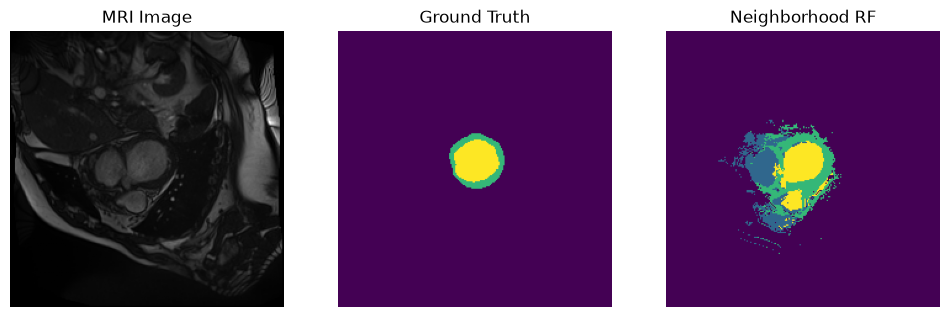

In [34]:
avg_3 = uniform_filter(val_image, size=3)
avg_7 = uniform_filter(val_image, size=7)

h, w = val_image.shape
yy, xx = np.indices(val_image.shape)

val_features_local = np.column_stack((
    val_image.ravel(),
    (xx / w).ravel(),
    (yy / h).ravel(),
    avg_3.ravel(),
    avg_7.ravel()
))

pred_mask_local = rf_seg_local.predict(val_features_local).reshape(val_image.shape)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask_local.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Neighborhood RF")
plt.axis("off")

plt.show()

### Extracting Features from Predicted Segmentations

We use the trained segmentation model to predict the ED and ES masks of each validation patient. From these masks, we calculate ventricular volumes, myocardium volume, and ejection fractions. These seven features will be passed to our existing Logistic Regression classifier to predict the cardiac condition.

In [35]:
predicted_features = []

for patient in sorted(val_patients):
    row = df[df["Patient"] == patient].iloc[0]
    patient_path = os.path.join(data_path, "training", patient)

    volumes = {}

    for phase in ["ED", "ES"]:
        frame = int(row[phase])
        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")

        nii = nib.load(image_path)
        image = nii.get_fdata()
        voxel_volume = np.prod(nii.header.get_zooms()[:3]) / 1000

        predicted_volume = np.zeros(image.shape, dtype=np.uint8)

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            predicted_volume[:, :, i] = rf_seg_local.predict(
                pixel_features
            ).reshape(slice_image.shape)

        volumes[phase] = {
            "LV": np.sum(predicted_volume == 3) * voxel_volume,
            "RV": np.sum(predicted_volume == 1) * voxel_volume,
            "MYO": np.sum(predicted_volume == 2) * voxel_volume
        }

    lv_ed = volumes["ED"]["LV"]
    lv_es = volumes["ES"]["LV"]
    rv_ed = volumes["ED"]["RV"]
    rv_es = volumes["ES"]["RV"]
    myo_ed = volumes["ED"]["MYO"]

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    predicted_features.append({
        "Patient": patient,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

predicted_features_df = pd.DataFrame(predicted_features)

print("Validation patients:", len(predicted_features_df))
print(predicted_features_df.head())

Validation patients: 20
      Patient Group       LV_ED       LV_ES       RV_ED       RV_ES  \
0  patient007   DCM  336.972656  324.773438  673.664062  672.996094   
1  patient008   DCM  213.159180  169.189453  357.763672  327.636719   
2  patient011   DCM  165.143634  153.267394  461.829295  461.146246   
3  patient015   DCM  183.967506  139.218653  364.495668  354.065484   
4  patient021   HCM  207.087097  137.399750  573.806183  560.827972   

       MYO_ED      LV_EF     RV_EF  
0  604.582031   3.620240  0.099155  
1  444.702148  20.627649  8.420909  
2  423.512447   7.191461  0.147901  
3  426.590776  24.324324  2.861538  
4  791.050140  33.651226  2.261776  


### Disease Classification Using Predicted Segmentations

We use the cardiac features extracted from the predicted segmentation masks as input to our previously trained Logistic Regression classifier. We evaluate classification accuracy and macro-F1 on the validation patients to measure the performance of the complete MRI-to-classification pipeline.

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

c_values = [0.01, 0.1, 1, 10, 100]
best_score = -1
best_c = None

for c in c_values:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=c, max_iter=1000, random_state=42)
    )

    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="f1_macro"
    )

    mean_score = scores.mean()
    print("C:", c, "Mean CV Macro-F1:", round(mean_score, 4))

    if mean_score > best_score:
        best_score = mean_score
        best_c = c

baseline_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=best_c, max_iter=1000, random_state=42)
)

baseline_classifier.fit(X_train, y_train)

X_predicted = predicted_features_df[feature_columns]
y_actual = predicted_features_df["Group"]

y_predicted = baseline_classifier.predict(X_predicted)

print()
print("Selected C:", best_c)
print("Validation Accuracy:", accuracy_score(y_actual, y_predicted))
print("Validation Macro-F1:", f1_score(y_actual, y_predicted, average="macro"))

print()
print(classification_report(y_actual, y_predicted, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_actual, y_predicted, labels=baseline_classifier.classes_))

C: 0.01 Mean CV Macro-F1: 0.8382
C: 0.1 Mean CV Macro-F1: 0.9045
C: 1 Mean CV Macro-F1: 0.9401
C: 10 Mean CV Macro-F1: 0.9401
C: 100 Mean CV Macro-F1: 0.9401

Selected C: 1
Validation Accuracy: 0.3
Validation Macro-F1: 0.16684491978609625

              precision    recall  f1-score   support

         DCM       0.31      1.00      0.47         4
         HCM       0.00      0.00      0.00         4
        MINF       0.00      0.00      0.00         4
         NOR       0.00      0.00      0.00         4
          RV       0.29      0.50      0.36         4

    accuracy                           0.30        20
   macro avg       0.12      0.30      0.17        20
weighted avg       0.12      0.30      0.17        20

Confusion Matrix:
[[4 0 0 0 0]
 [1 0 0 0 3]
 [3 0 0 0 1]
 [3 0 0 0 1]
 [2 0 0 0 2]]


### Classical Pipeline Results

The Random Forest segmentation model achieved a mean Dice score of 0.4046 on the 20 validation patients. The left ventricle had the highest Dice score (0.5589), followed by the myocardium (0.3378) and right ventricle (0.3169).

Using features extracted from these predicted masks, the Logistic Regression classifier achieved 30% accuracy and a macro-F1 of 0.1668. In comparison, cross-validation using features extracted from expert segmentation masks achieved a macro-F1 of 0.9401.

The results suggest that inaccurate segmentation significantly affects the cardiac measurements used for classification. Although the complete pipeline performs poorly, it provides a classical baseline for comparison with more advanced approaches, such as CNN-based segmentation.

### Final Segmentation Model

After selecting the segmentation approach using validation results, we retrain the Random Forest on all 100 training patients. We use the same five pixel features and hyperparameters before evaluating the complete pipeline on the 50 test patients.

In [39]:
X_seg_final = []
y_seg_final = []

rng = np.random.default_rng(42)

for image, mask in zip(seg_images, seg_masks):
    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    h, w = image.shape
    yy, xx = np.indices(image.shape)

    avg_3 = uniform_filter(image, size=3)
    avg_7 = uniform_filter(image, size=7)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / w).ravel(),
        (yy / h).ravel(),
        avg_3.ravel(),
        avg_7.ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_final.append(pixel_features[selected])
        y_seg_final.append(labels[selected])

X_seg_final = np.vstack(X_seg_final)
y_seg_final = np.concatenate(y_seg_final)

print("Training pixels:", X_seg_final.shape)
print("Class counts:", np.unique(y_seg_final, return_counts=True))

Training pixels: (1930313, 5)
Class counts: (array([0, 1, 2, 3]), array([951000, 285354, 360595, 333364]))


### Training the Final Segmentation Model

We train the final Random Forest segmentation model using all 100 training patients. We keep the same hyperparameters selected during development and will evaluate the model on the 50 official testing patients.

In [40]:
rf_seg_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_final.fit(X_seg_final, y_seg_final)

print("Final Random Forest training completed")
print("Training pixels:", len(X_seg_final))
print("Number of features:", X_seg_final.shape[1])

Final Random Forest training completed
Training pixels: 1930313
Number of features: 5


### Final Segmentation Evaluation

We evaluate the final Random Forest segmentation model on the 50 official test patients. We calculate Dice scores for the right ventricle, myocardium, and left ventricle by comparing the predicted masks with the expert segmentation masks. The test patients were not used during training or model selection.

In [41]:
test_dice_results = []

for _, row in df[df["Split"] == "testing"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "testing", patient)

    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for phase in ["ED", "ES"]:
        frame = int(row[phase])

        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")
        mask_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}_gt.nii.gz")

        image = nib.load(image_path).get_fdata()
        mask = nib.load(mask_path).get_fdata()

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            prediction = rf_seg_final.predict(pixel_features).reshape(slice_image.shape)
            actual_slice = mask[:, :, i]

            for label in range(1, 4):
                predicted = prediction == label
                actual = actual_slice == label

                intersections[label - 1] += np.sum(predicted & actual)
                predicted_counts[label - 1] += np.sum(predicted)
                actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    test_dice_results.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

test_dice_df = pd.DataFrame(test_dice_results)

print("Mean Dice on Test Patients:")
print(test_dice_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Overall Mean Dice:", round(
    test_dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4
))

Mean Dice on Test Patients:
RV            0.3400
Myocardium    0.3428
LV            0.5379
dtype: float64
Overall Mean Dice: 0.4069


### Extracting Cardiac Features from Test Predictions

We use the final Random Forest segmentation model to predict ED and ES masks for the 50 test patients. From these predicted masks, we calculate the same seven cardiac measurements used by our Logistic Regression classifier. This allows us to evaluate disease classification using only the MRI images and the ED/ES frame information.

In [42]:
test_predicted_features = []

for _, row in df[df["Split"] == "testing"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "testing", patient)

    volumes = {}

    for phase in ["ED", "ES"]:
        frame = int(row[phase])
        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")

        nii = nib.load(image_path)
        image = nii.get_fdata()
        voxel_volume = np.prod(nii.header.get_zooms()[:3]) / 1000

        predicted_volume = np.zeros(image.shape, dtype=np.uint8)

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            predicted_volume[:, :, i] = rf_seg_final.predict(
                pixel_features
            ).reshape(slice_image.shape)

        volumes[phase] = {
            "LV": np.sum(predicted_volume == 3) * voxel_volume,
            "RV": np.sum(predicted_volume == 1) * voxel_volume,
            "MYO": np.sum(predicted_volume == 2) * voxel_volume
        }

    lv_ed = volumes["ED"]["LV"]
    lv_es = volumes["ES"]["LV"]
    rv_ed = volumes["ED"]["RV"]
    rv_es = volumes["ES"]["RV"]
    myo_ed = volumes["ED"]["MYO"]

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    test_predicted_features.append({
        "Patient": patient,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

test_predicted_features_df = pd.DataFrame(test_predicted_features)

print("Test patients:", len(test_predicted_features_df))
print(test_predicted_features_df.head())

Test patients: 50
      Patient Group       LV_ED       LV_ES       RV_ED       RV_ES  \
0  patient101   DCM  285.636200  240.551331  526.995021  521.234924   
1  patient102   NOR  170.776367  125.585938  581.884766  583.032227   
2  patient103  MINF  157.788086  130.590820  278.125000  255.444336   
3  patient104   HCM  137.218600   67.235432  352.514041  329.092858   
4  patient105   HCM  140.818274   94.392972  444.907306  426.839557   

       MYO_ED      LV_EF     RV_EF  
0  556.091584  15.784018  1.093008  
1  328.540039  26.461758 -0.197197  
2  414.282227  17.236577  8.154846  
3  379.673641  51.001226  6.644043  
4  468.946226  32.968237  4.061014  


### Final Classification Evaluation

We use the cardiac measurements extracted from the Random Forest's predicted segmentation masks to classify the 50 test patients. The Logistic Regression classifier was trained on all 100 training patients using features extracted from expert masks. We evaluate the complete pipeline using accuracy, macro-F1, a classification report, and a confusion matrix.

In [43]:
X_test_rf = test_predicted_features_df[feature_columns]
y_test_rf = test_predicted_features_df["Group"]

y_pred_rf = final_model.predict(X_test_rf)

print("Model 2 Test Accuracy:", accuracy_score(y_test_rf, y_pred_rf))
print("Model 2 Test Macro-F1:", f1_score(y_test_rf, y_pred_rf, average="macro"))

print()
print(classification_report(y_test_rf, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test_rf, y_pred_rf, labels=final_model.classes_))

Model 2 Test Accuracy: 0.28
Model 2 Test Macro-F1: 0.1627586206896552

              precision    recall  f1-score   support

         DCM       0.27      0.80      0.40        10
         HCM       0.00      0.00      0.00        10
        MINF       0.00      0.00      0.00        10
         NOR       0.00      0.00      0.00        10
          RV       0.32      0.60      0.41        10

    accuracy                           0.28        50
   macro avg       0.12      0.28      0.16        50
weighted avg       0.12      0.28      0.16        50

Confusion Matrix:
[[8 0 0 0 2]
 [6 0 0 0 4]
 [9 0 0 0 1]
 [3 0 1 0 6]
 [4 0 0 0 6]]


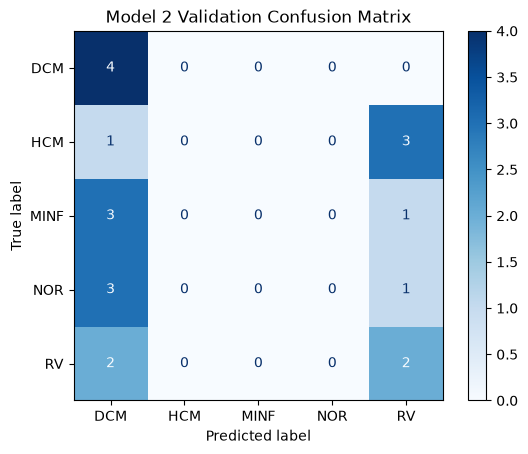

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

classes = ["DCM", "HCM", "MINF", "NOR", "RV"]

cm = np.array([
    [4, 0, 0, 0, 0],
    [1, 0, 0, 0, 3],
    [3, 0, 0, 0, 1],
    [3, 0, 0, 0, 1],
    [2, 0, 0, 0, 2]
])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(cmap="Blues")

plt.title("Model 2 Validation Confusion Matrix")
plt.show()

### Final Classical Model Results

Both classical approaches were evaluated on the same 50 official test patients.

Model 1, which uses cardiac measurements extracted from expert segmentation masks, achieved 90% classification accuracy and a macro-F1 of 0.8999.

Model 2 uses a Random Forest to automatically segment the MRI images before extracting the same cardiac measurements. Its segmentation model achieved a mean Dice score of 0.4069, while the complete classification pipeline achieved 28% accuracy and a macro-F1 of 0.1628.

The large difference between the two models suggests that segmentation quality is important for accurate disease classification. The Random Forest produces inaccurate cardiac measurements, particularly for the right ventricle and myocardium, which affects the classifier's predictions. Additionally, the classifier was trained using expert-mask measurements rather than predicted-mask measurements, creating a mismatch between training and testing inputs.

Although Model 2 performs poorly, it provides a classical automatic-segmentation baseline for comparison with the CNN-based approach.